# BrainScan AI — Brain MRI Classification

## 1. Project Introduction

BrainScan AI is a Deep Learning project that aims to classify brain MRI images using a Convolutional Neural Network (CNN).

The dataset contains four classes:
- **Glioma**
- **Meningioma**
- **No Tumor**
- **Pituitary**

The objective of this notebook is to explore the dataset, understand its structure, inspect image quality, and prepare for the preprocessing and model training stages.

### Objectives
- Identify the dataset classes.
- Count images in each class.
- Inspect image file extensions.
- Display sample MRI images.
- Check for unreadable or corrupted images.
- Investigate class imbalance.

### Libraries
- `Pathlib`: file and directory management.
- `OpenCV`: image loading and resizing.
- `NumPy`: numerical operations and image arrays.
- `Matplotlib`: data visualization.
- `Pandas`: organizing dataset statistics.

## 2. Import Libraries

In this section, we import the Python libraries required for dataset exploration.

- `Path` helps us navigate directories and access files.
- `Counter` helps count image files and file extensions.
- `cv2` allows us to load and process images.
- `NumPy` supports numerical operations.
- `Pandas` organizes the results in tables.
- `Matplotlib` displays MRI images and charts.

Importing libraries at the beginning makes the notebook easier to maintain and understand.

In [2]:
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Define the Dataset Path

The MRI dataset is stored in `data/brain_mri/Data/`.

Each subdirectory represents a class, and the images inside that directory inherit its label.

Because this notebook is inside the `notebooks/` directory, we use `../data/brain_mri/Data` to access the dataset.

We first verify that the directory exists before attempting to load any images.

In [3]:
DATA_DIR = Path("../data/brain_mri/Data")

print("Dataset exists:", DATA_DIR.exists())
print("Dataset path:", DATA_DIR.resolve())

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Dataset directory not found: {DATA_DIR.resolve()}")

Dataset exists: True
Dataset path: /home/lahcen404/Desktop/YouCode-Y2/BrainScanAI/data/brain_mri/Data


## 4. Explore Dataset Classes

In supervised learning, a **label** is the correct category associated with an example.

In this dataset, the folder names provide the labels. For example, an image inside the `glioma` folder receives the label `glioma`.

We discover the class names automatically instead of hardcoding them. This makes our code more reusable if the dataset changes.

At this stage, we inspect the directory structure without loading the actual image pixels.

In [4]:
classes = sorted(
    folder.name
    for folder in DATA_DIR.iterdir()
    if folder.is_dir()
)

print("Classes : ", classes)
print("Number of classes :", len(classes))

for class_name in classes:
    print(f"- {class_name}")

Classes :  ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of classes : 4
- glioma
- meningioma
- notumor
- pituitary


## 5. Count Images in Each Class

Before training a model, we need to understand how many examples are available for each class.

A **class imbalance** occurs when some classes contain significantly more images than others.

For example, if one class contains 3,000 images and another contains only 300, the model may learn the majority class more easily.

Here, we count files with the supported image extensions. This is an initial count; we will verify whether the images are readable in a later section.

In [5]:
VALID_EXTENSIONS = {".jpeg", ".jpg", ".bmp", ".png"}

class_counts = {}

for class_name in classes:
    class_dir = DATA_DIR / class_name
    
    image_files = [
        file for file in class_dir.iterdir()
        if file.is_file()
        and file.suffix.lower() in VALID_EXTENSIONS
    ]
    
    
    class_counts[class_name] = len(image_files)

class_counts_df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Number of Images"]
)

display(class_counts_df)

print("Total supported image files:", sum(class_counts.values()))

,Class,Number of Images
0,glioma,1621
1,meningioma,1645
2,notumor,2000
3,pituitary,1757


Total supported image files: 7023


## 6. Visualize Class Distribution

A table provides exact counts, while a bar chart makes differences between classes easier to see.

We use Matplotlib to plot the number of supported image files in each class.

This visualization helps us decide whether we need to investigate class imbalance and consider techniques such as class weights or training-data augmentation.

We should not rebalance the dataset automatically without first examining the distribution.

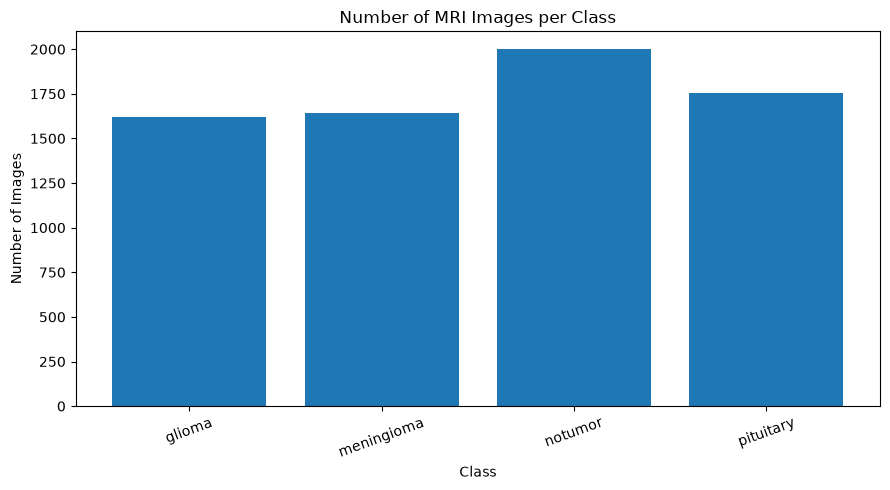

In [6]:
plt.figure(figsize=(9, 5))

plt.bar(
    class_counts_df["Class"],
    class_counts_df["Number of Images"]
)

plt.title("Number of MRI Images per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 7. Inspect Image Extensions

Image files may use different extensions, such as `.jpg`, `.jpeg`, `.png`, and `.bmp`.

Our project accepts these four formats. We inspect the extensions present in the dataset to identify unsupported files.

The extension alone does not guarantee that a file contains a valid image. We will check whether OpenCV can actually decode each file in the image-loading stage.

In [7]:
extension_counts = Counter()

for class_name in classes:
    class_dir = DATA_DIR / class_name

    for file in class_dir.iterdir():
        if file.is_file():
            extension_counts[file.suffix.lower() or "[no extension]"] += 1

extensions_df = pd.DataFrame(
    extension_counts.items(),
    columns=["Extension", "Number of Files"]
).sort_values("Number of Files", ascending=False)

display(extensions_df)

,Extension,Number of Files
0,.jpg,7023


## 8. Display Sample MRI Images

Visual inspection helps us understand the dataset before applying preprocessing.

We display one sample image from each class, using the folder name as its label.

OpenCV loads color images in BGR channel order. Matplotlib expects RGB, so we convert the channel order before displaying the image.

If an image cannot be decoded, OpenCV returns `None`. We handle that case instead of attempting to display invalid image data.

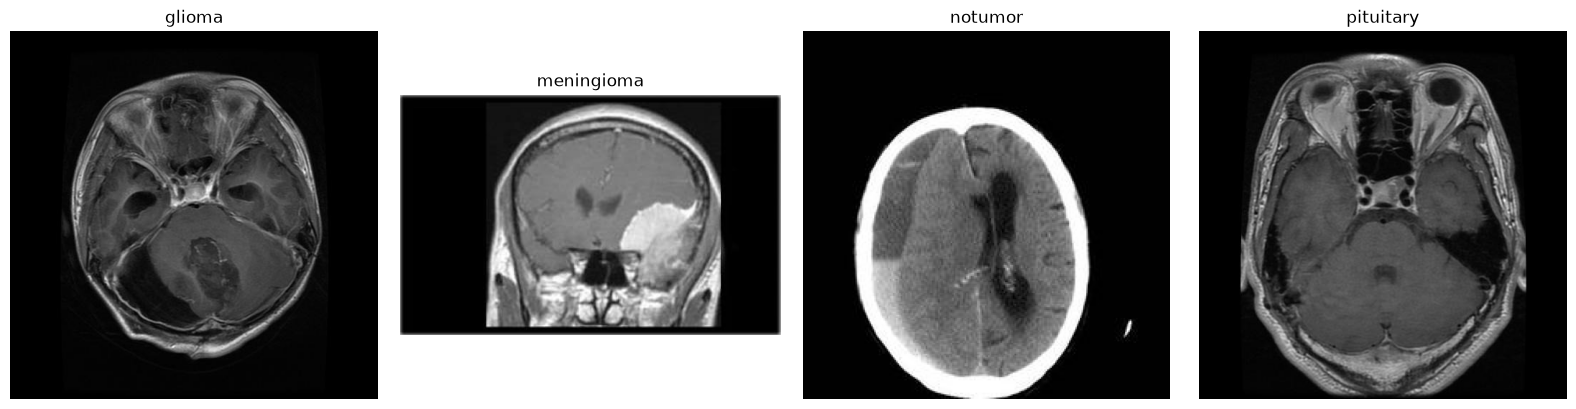

In [8]:
fig, axes = plt.subplots(
    1, len(classes),
    figsize=(4 * len(classes), 4)
)

axes = np.atleast_1d(axes)

for ax, class_name in zip(axes, classes):
    class_dir = DATA_DIR / class_name

    image_files = sorted(
        file for file in class_dir.iterdir()
        if file.is_file()
        and file.suffix.lower() in VALID_EXTENSIONS
    )

    ax.set_title(class_name)
    ax.axis("off")

    if not image_files:
        ax.set_title(f"{class_name}\nNo images found")
        continue

    image = cv2.imread(str(image_files[0]))

    if image is not None:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        ax.imshow(image)
    else:
        ax.set_title(f"{class_name}\nUnreadable image")

plt.tight_layout()
plt.show()

## 9. Initial Conclusions

After running the previous sections, summarize:

- The number of classes found.
- The number of supported image files per class.
- The file extensions present.
- Whether sample images can be displayed correctly.
- Whether the class distribution appears imbalanced.
- Any issues that require investigation before preprocessing.

These observations will guide the next stage: loading valid images, handling corrupted files, resizing images to 224 × 224, and keeping each image aligned with its correct label.

### 10. Validate MRI Images

**Objective:** Check whether the image files can actually be opened by OpenCV.

A file can have a `.jpg` extension but still contain corrupted or invalid image data. We use `cv2.imread()` to attempt to load each image.

- If the image loads successfully, `cv2.imread()` returns a NumPy array.
- If the image cannot be loaded, it returns `None`.

We will count valid and unreadable images for each class. This helps us identify potential problems before preprocessing and CNN training.

In [9]:
VALID_EXTENSIONS = {".jpeg", ".jpg", ".bmp", ".png"}

valid_images = []
unreadable_images = []

for class_name in classes:
    class_dir = DATA_DIR / class_name

    for file in class_dir.iterdir():
        if not file.is_file():
            continue

        if file.suffix.lower() not in VALID_EXTENSIONS:
            continue

        image = cv2.imread(str(file))

        if image is None:
            unreadable_images.append({
                "path": str(file),
                "class": class_name
            })
        else:
            valid_images.append({
                "path": str(file),
                "class": class_name
            })

print("Valid images:", len(valid_images))
print("Unreadable images:", len(unreadable_images))

Valid images: 7023
Unreadable images: 0


In [10]:
unreadable_df = pd.DataFrame(unreadable_images)

if unreadable_df.empty:
    print("All supported image files were readable!")
else:
    display(unreadable_df.head(10))

All supported image files were readable!


In [11]:
valid_counts = (
    pd.DataFrame(valid_images)
    .groupby("class")
    .size()
    .reset_index(name="valid_images")
)

print(valid_counts)

        class  valid_images
0      glioma          1621
1  meningioma          1645
2     notumor          2000
3   pituitary          1757


### 11. Load and Resize MRI Images

**Objective:** Load all valid MRI images, resize them to `224 × 224` pixels, and store them with their corresponding labels.

MRI images can have different dimensions. A CNN expects a consistent input shape, so we resize every image.

- **Load:** Read the image using OpenCV.
- **Resize:** Convert it to `224 × 224` pixels.
- **Store:** Add the image to `X` and its class label to `y`.

We will keep the images in BGR format for now because the CNN can learn from these channel values. We will convert them to NumPy arrays and inspect their shapes before continuing.

In [12]:
IMAGE_SIZE = (224,224)

VALID_EXTENSIONS = {".jpeg", ".jpg", ".bmp", ".png"}

X = []
y = []

failed_images = []

for class_name in classes:
    class_dir = DATA_DIR / class_name
    
    for file in sorted(class_dir.iterdir()):
        
        if not file.is_file():
            continue
        
        if file.suffix.lower() not in VALID_EXTENSIONS:
            continue
        
        images = cv2.imread(str(file))
        
        if image is None:
            failed_images.append(str(file))
            continue
        
        image = cv2.resize(image,IMAGE_SIZE)
        
        X.append(image)
        y.append(class_name)
        
print("Images loaded:", len(X))
print("Labels loaded:", len(y))
print("Failed images:", len(failed_images))

Images loaded: 7023
Labels loaded: 7023
Failed images: 0


### Convert to NumPy arrays

In [13]:
X = np.array(X,dtype=np.uint8)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Image data type:", X.dtype)
print("Classes:", np.unique(y))

X shape: (7023, 224, 224, 3)
y shape: (7023,)
Image data type: uint8
Classes: ['glioma' 'meningioma' 'notumor' 'pituitary']


### Display one processed image

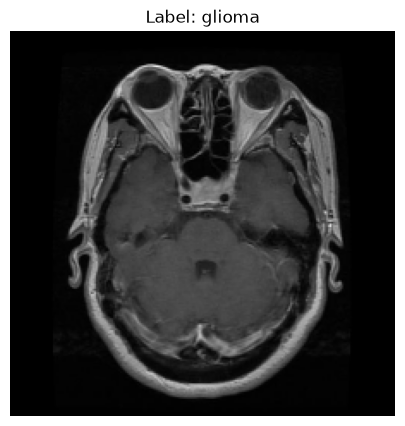

In [14]:
plt.figure(figsize=(5, 5))

plt.imshow(cv2.cvtColor(X[0], cv2.COLOR_BGR2RGB))
plt.title(f"Label: {y[0]}")
plt.axis("off")

plt.show()